## **setup and download**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.environ["KAGGLE_API_TOKEN"] = "ur_api_token"

!pip install -U kaggle -q
!kaggle datasets download -d nih-chest-xrays/data -p /content/nih
!df -h /content | tail -1

Mounted at /content/drive
Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
License(s): CC0-1.0
100% 42.0G/42.0G [05:51<00:00, 128MB/s]

overlay         113G   43G   71G  38% /


# **Labels and the splits**

In [3]:
import zipfile, io, os, numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit

ZIP = "/content/nih/data.zip"
z = zipfile.ZipFile(ZIP)
names = z.namelist()
find = lambda base: [n for n in names if os.path.basename(n) == base][0]

df = pd.read_csv(z.open(find("Data_Entry_2017.csv")))
train_val_files = set(z.read(find("train_val_list.txt")).decode().split())
test_files = set(z.read(find("test_list.txt")).decode().split())
img_member = {os.path.basename(n): n for n in names if n.lower().endswith(".png")}

CLASSES = ["Atelectasis","Cardiomegaly","Effusion","Infiltration","Mass","Nodule","Pneumonia",
           "Pneumothorax","Consolidation","Edema","Emphysema","Fibrosis","Pleural_Thickening","Hernia"]
for c in CLASSES:
    df[c] = df["Finding Labels"].str.contains(c).astype(np.float32)
df["sex"] = (df["Patient Gender"] == "M").astype(int)
df["view"] = (df["View Position"] == "PA").astype(int)
df["age"] = df["Patient Age"].clip(upper=100)
df = df[df["Image Index"].isin(img_member)].reset_index(drop=True)
df["row"] = np.arange(len(df))

tv = df[df["Image Index"].isin(train_val_files)]
test_df = df[df["Image Index"].isin(test_files)]
gss = GroupShuffleSplit(n_splits=1, test_size=0.12, random_state=42)
tr_i, va_i = next(gss.split(tv, groups=tv["Patient ID"]))
train_df, val_df = tv.iloc[tr_i], tv.iloc[va_i]
assert not set(train_df["Patient ID"]) & set(val_df["Patient ID"])
assert not set(tv["Patient ID"]) & set(test_df["Patient ID"])


print("=" * 55)
print("NIH CHEST X-RAY DATASET SUMMARY")
print("=" * 55)

print(f"Total CSV records:        {len(pd.read_csv(z.open(find('Data_Entry_2017.csv')))):,}")
print(f"Images found in ZIP:      {len(img_member):,}")
print(f"Official train/val list:  {len(train_val_files):,}")
print(f"Official test list:       {len(test_files):,}")
print(f"Usable dataset records:   {len(df):,}")

print("\n" + "=" * 55)
print("FINAL DATASET SPLIT")
print("=" * 55)

print(f"Training images:    {len(train_df):,}")
print(f"Validation images:  {len(val_df):,}")
print(f"Testing images:     {len(test_df):,}")

print("\nPercentage of usable images:")
print(f"Training:    {len(train_df)/len(df)*100:.2f}%")
print(f"Validation:  {len(val_df)/len(df)*100:.2f}%")
print(f"Testing:     {len(test_df)/len(df)*100:.2f}%")

print("\nUnique patients:")
print(f"Training:    {train_df['Patient ID'].nunique():,}")
print(f"Validation:  {val_df['Patient ID'].nunique():,}")
print(f"Testing:     {test_df['Patient ID'].nunique():,}")

print("\nPatient overlap checks:")
print("Train vs Validation:",
      len(set(train_df["Patient ID"]) & set(val_df["Patient ID"])))
print("Train vs Test:",
      len(set(train_df["Patient ID"]) & set(test_df["Patient ID"])))
print("Validation vs Test:",
      len(set(val_df["Patient ID"]) & set(test_df["Patient ID"])))

NIH CHEST X-RAY DATASET SUMMARY
Total CSV records:        112,120
Images found in ZIP:      112,120
Official train/val list:  86,524
Official test list:       25,596
Usable dataset records:   112,120

FINAL DATASET SPLIT
Training images:    76,277
Validation images:  10,247
Testing images:     25,596

Percentage of usable images:
Training:    68.03%
Validation:  9.14%
Testing:     22.83%

Unique patients:
Training:    24,647
Validation:  3,361
Testing:     2,797

Patient overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


# **Shrink every image into one array**

In [4]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

S = 256
OUT = "/content/nih_256.npy"
arr = np.lib.format.open_memmap(OUT, mode="w+", dtype=np.uint8, shape=(len(df), S, S))

def decode(b):
    im = Image.open(io.BytesIO(b)).convert("L").resize((S, S), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

members = [img_member[n] for n in df["Image Index"]]
CH = 256
with ThreadPoolExecutor(4) as ex:
    for s in range(0, len(members), CH):
        blobs = [z.read(m) for m in members[s:s+CH]]
        arr[s:s+len(blobs)] = np.stack(list(ex.map(decode, blobs)))
        if (s // CH) % 40 == 0: print(f"{s}/{len(members)}")
arr.flush()

os.makedirs("/content/drive/MyDrive/cxr", exist_ok=True)
!cp /content/nih_256.npy /content/drive/MyDrive/cxr/nih_256.npy
df.drop(columns=["Finding Labels"]).to_csv("/content/drive/MyDrive/cxr/meta.csv", index=False)

0/112120
10240/112120
20480/112120
30720/112120
40960/112120
51200/112120
61440/112120
71680/112120
81920/112120
92160/112120
102400/112120


# **training**

In [5]:
import torch, torch.nn as nn, torchvision
from sklearn.metrics import roc_auc_score

arr = np.load("/content/nih_256.npy", mmap_mode="r")
dev = "cuda"

class DS(torch.utils.data.Dataset):
    def __init__(self, d, train): self.rows, self.Y, self.train = d["row"].values, d[CLASSES].values.astype(np.float32), train
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        x = torch.from_numpy(np.array(arr[self.rows[i]])).float().div(255).unsqueeze(0)
        if self.train:
            r, c = np.random.randint(0, S-224+1, 2)
            x = x[:, r:r+224, c:c+224] * np.random.uniform(0.9, 1.1)
        else:
            o = (S-224)//2
            x = x[:, o:o+224, o:o+224]
        return ((x - 0.5) / 0.25).repeat(3, 1, 1), torch.from_numpy(self.Y[i])

mk = lambda d, t: torch.utils.data.DataLoader(DS(d, t), batch_size=64, shuffle=t, num_workers=2, pin_memory=True, drop_last=t)
dl_tr, dl_va, dl_te = mk(train_df, True), mk(val_df, False), mk(test_df, False)
Yva, Yte = val_df[CLASSES].values, test_df[CLASSES].values

model = torchvision.models.densenet121(weights="IMAGENET1K_V1")
model.classifier = nn.Linear(1024, len(CLASSES))
model = model.to(dev).to(memory_format=torch.channels_last)

EPOCHS = 5
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=EPOCHS*len(dl_tr))
lossf = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def predict(dl):
    model.eval(); out = []
    for x, _ in dl:
        with torch.autocast("cuda"):
            out.append(model(x.to(dev, non_blocking=True)).float().cpu())
    return torch.cat(out).numpy()

def auroc(Y, P):
    return {c: roc_auc_score(Y[:, i], P[:, i]) for i, c in enumerate(CLASSES) if 0 < Y[:, i].sum() < len(Y)}


CKPT = "/content/drive/MyDrive/cxr/best.pt"
best = -1

for ep in range(EPOCHS):
    model.train()
    total_loss = 0
    total_images = 0

    for x, y in dl_tr:
        x = x.to(dev, non_blocking=True)
        y = y.to(dev, non_blocking=True)

        with torch.autocast("cuda"):
            loss = lossf(model(x), y)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()

        total_loss += loss.item() * x.size(0)
        total_images += x.size(0)

    avg_loss = total_loss / total_images

    predictions = predict(dl_va)
    scores = auroc(Yva, predictions)
    mean_auc = np.mean(list(scores.values()))

    print("\n" + "=" * 50)
    print(f"EPOCH {ep + 1} / {EPOCHS}")
    print("=" * 50)

    print(f"Average training loss: {avg_loss:.4f}")
    print(f"Validation mean AUROC: {mean_auc:.4f}")

    print("\nAUROC for each disease:")
    for disease, score in scores.items():
        print(f"  {disease:<20} {score:.4f}")

    if mean_auc > best:
        best = mean_auc
        torch.save(model.state_dict(), CKPT)
        print("\nNew best model saved!")

    print(f"Best validation AUROC so far: {best:.4f}")


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 120MB/s]



EPOCH 1 / 5
Average training loss: 0.2157
Validation mean AUROC: 0.7935

AUROC for each disease:
  Atelectasis          0.7819
  Cardiomegaly         0.8643
  Effusion             0.8841
  Infiltration         0.6694
  Mass                 0.8008
  Nodule               0.7167
  Pneumonia            0.6724
  Pneumothorax         0.8361
  Consolidation        0.7961
  Edema                0.8931
  Emphysema            0.8095
  Fibrosis             0.8053
  Pleural_Thickening   0.7803
  Hernia               0.7982

New best model saved!
Best validation AUROC so far: 0.7935

EPOCH 2 / 5
Average training loss: 0.1355
Validation mean AUROC: 0.8183

AUROC for each disease:
  Atelectasis          0.8122
  Cardiomegaly         0.8838
  Effusion             0.8984
  Infiltration         0.6960
  Mass                 0.8317
  Nodule               0.7442
  Pneumonia            0.7256
  Pneumothorax         0.8609
  Consolidation        0.8105
  Edema                0.9056
  Emphysema            0

# **Test results and the ML (stacking)**

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier

model.load_state_dict(torch.load(CKPT))
Pva, Pte = predict(dl_va), predict(dl_te)
dl_auc = auroc(Yte, Pte)
print("DL-only test mean AUROC:", round(np.mean(list(dl_auc.values())), 4))

meta = lambda d: d[["age", "sex", "view"]].values
Fva, Fte = np.hstack([Pva, meta(val_df)]), np.hstack([Pte, meta(test_df)])
stack_auc = {}
for i, c in enumerate(CLASSES):
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150)
    gb.fit(Fva, Yva[:, i])                       # trained on VAL, never on train
    stack_auc[c] = roc_auc_score(Yte[:, i], gb.predict_proba(Fte)[:, 1])

res = pd.DataFrame({"DL only": dl_auc, "DL + metadata (GB)": stack_auc}).round(3)
res.loc["MEAN"] = res.mean().round(3)
print(res)

DL-only test mean AUROC: 0.8148
                    DL only  DL + metadata (GB)
Atelectasis           0.782               0.780
Cardiomegaly          0.887               0.874
Effusion              0.828               0.828
Infiltration          0.701               0.709
Mass                  0.832               0.823
Nodule                0.774               0.764
Pneumonia             0.724               0.702
Pneumothorax          0.860               0.849
Consolidation         0.754               0.741
Edema                 0.845               0.831
Emphysema             0.910               0.890
Fibrosis              0.827               0.816
Pleural_Thickening    0.783               0.773
Hernia                0.901               0.861
MEAN                  0.815               0.803


# **A fairer ML comparison (simple model + metadata-only baseline)**

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Mva, Mte = meta(val_df), meta(test_df)
lr_auc, meta_auc = {}, {}
for i, c in enumerate(CLASSES):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=1000))
    clf.fit(np.hstack([Pva[:, [i]], Mva]), Yva[:, i])
    lr_auc[c] = roc_auc_score(Yte[:, i], clf.predict_proba(np.hstack([Pte[:, [i]], Mte]))[:, 1])
    # metadata only (how much do age/sex/view alone tell me?)
    gbm = HistGradientBoostingClassifier(max_depth=2, max_iter=100, learning_rate=0.05)
    gbm.fit(Mva, Yva[:, i])
    meta_auc[c] = roc_auc_score(Yte[:, i], gbm.predict_proba(Mte)[:, 1])

res2 = pd.DataFrame({"DL only": dl_auc, "DL+meta (GB)": stack_auc,
                     "DL+meta (LogReg)": lr_auc, "Metadata only": meta_auc}).round(3)
res2.loc["MEAN"] = res2.mean().round(3)
print(res2)

                    DL only  DL+meta (GB)  DL+meta (LogReg)  Metadata only
Atelectasis           0.782         0.780             0.782          0.561
Cardiomegaly          0.887         0.874             0.886          0.506
Effusion              0.828         0.828             0.829          0.531
Infiltration          0.701         0.709             0.704          0.604
Mass                  0.832         0.823             0.832          0.505
Nodule                0.774         0.764             0.774          0.565
Pneumonia             0.724         0.702             0.723          0.524
Pneumothorax          0.860         0.849             0.856          0.588
Consolidation         0.754         0.741             0.751          0.612
Edema                 0.845         0.831             0.846          0.707
Emphysema             0.910         0.890             0.906          0.537
Fibrosis              0.827         0.816             0.823          0.686
Pleural_Thickening    0.7

# **Grad-CAM (where is the model looking?)**

Saved: /content/drive/MyDrive/cxr/results/gradcam_Cardiomegaly.png


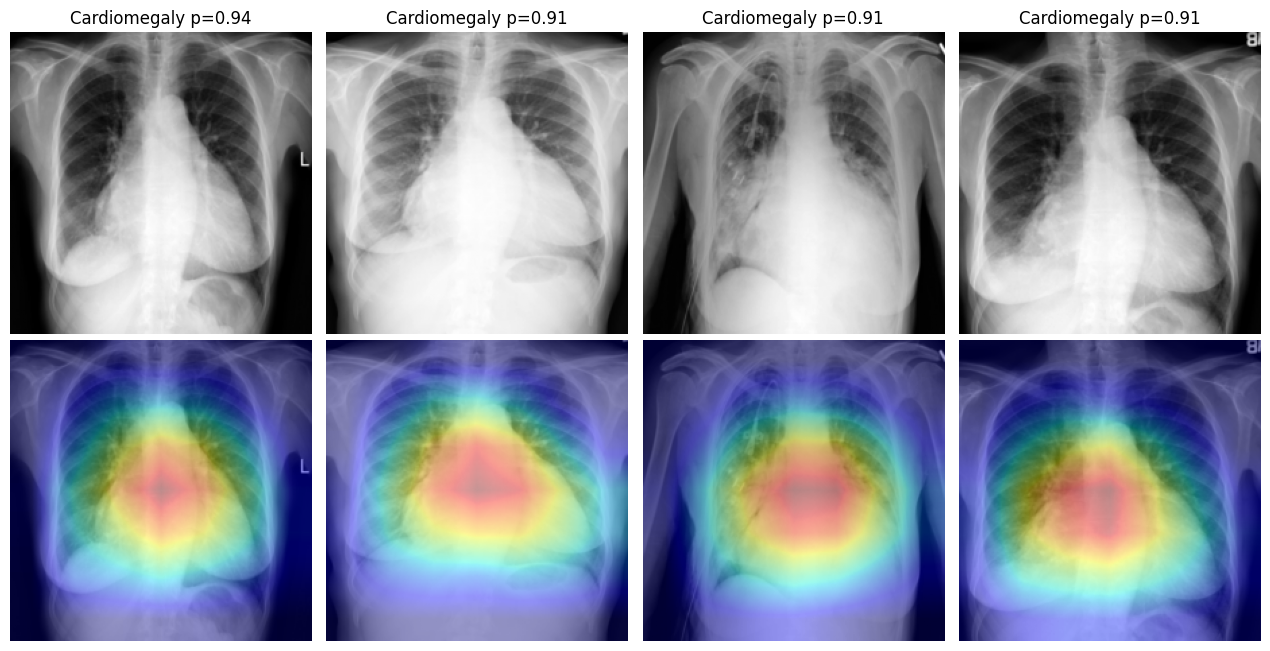

Saved: /content/drive/MyDrive/cxr/results/gradcam_Effusion.png


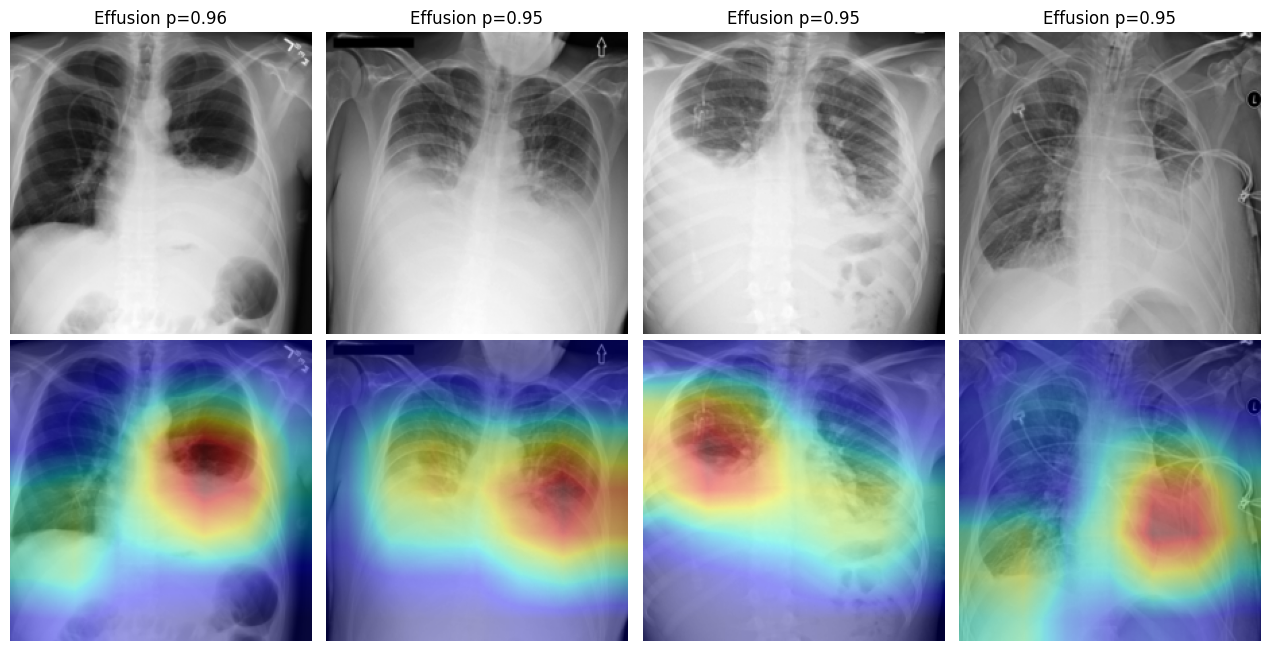

Saved: /content/drive/MyDrive/cxr/results/gradcam_Pneumothorax.png


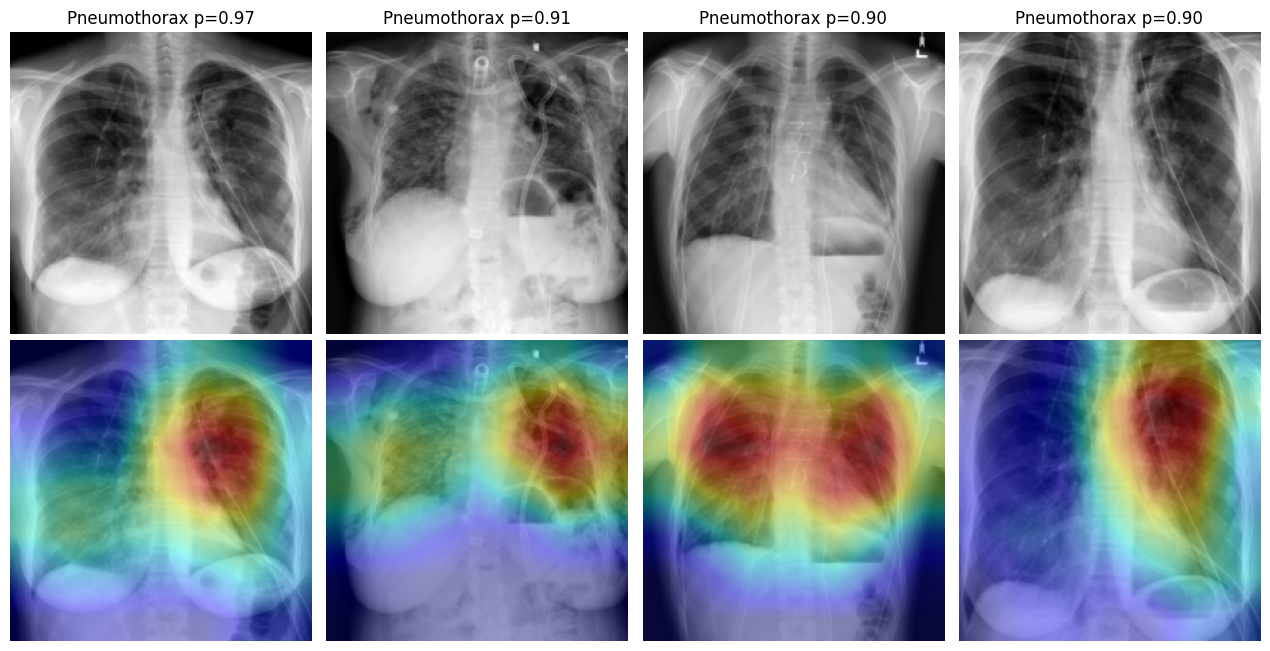

In [26]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

def gradcam(x, cls_idx):
    model.eval()
    x = x.unsqueeze(0).to(dev).requires_grad_(True)
    feats = model.features(x)
    feats.retain_grad()
    out = model.classifier(F.adaptive_avg_pool2d(F.relu(feats), 1).flatten(1))
    model.zero_grad()
    out[0, cls_idx].backward()
    w = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(out[0, cls_idx]).item()

ds_te = DS(test_df, False)


import os
import matplotlib.pyplot as plt

SAVE_DIR = "/content/drive/MyDrive/cxr/results"
os.makedirs(SAVE_DIR, exist_ok=True)

def show_cams(cls, n=4):
    ci = CLASSES.index(cls)
    idx = np.where(Yte[:, ci] == 1)[0]
    idx = idx[np.argsort(-Pte[idx, ci])][:n]

    if len(idx) == 0:
        print(f"No positive images found for {cls}")
        return

    fig, axs = plt.subplots(
        2, len(idx),
        figsize=(3.2 * len(idx), 6.6),
        squeeze=False
    )

    for j, i in enumerate(idx):
        x, _ = ds_te[i]
        cam, p = gradcam(x, ci)
        img = x[0].numpy()

        axs[0, j].imshow(img, cmap="gray")
        axs[0, j].axis("off")
        axs[0, j].set_title(f"{cls} p={p:.2f}")

        axs[1, j].imshow(img, cmap="gray")
        axs[1, j].imshow(cam, cmap="jet", alpha=0.4)
        axs[1, j].axis("off")

    plt.tight_layout()

    filename = f"{SAVE_DIR}/gradcam_{cls}.png"
    fig.savefig(filename, dpi=300, bbox_inches="tight")

    print(f"Saved: {filename}")

    plt.show()
    plt.close(fig)


for disease in ["Cardiomegaly", "Effusion", "Pneumothorax"]:
    show_cams(disease)

# **checking**

In [12]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

ci = CLASSES.index("Pneumothorax")

y_true = Yte[:, ci].astype(int)
probs = torch.sigmoid(
    torch.tensor(Pte[:, ci])).numpy()

print("PNEUMOTHORAX PERFORMANCE")
print("=" * 65)
print(f"Positive test labels: {y_true.sum():,}")
print(f"Negative test labels: {(y_true == 0).sum():,}")
print(f"AUROC: {roc_auc_score(y_true, probs):.4f}")
print()

print(f"{'Threshold':<12} {'Sensitivity':<14} {'Precision':<12} {'F1':<10} {'FP':<8} {'FN':<8}")
print("-" * 65)

for threshold in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred = (probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(
        f"{threshold:<12.2f}"
        f"{sensitivity:<14.3f}"
        f"{precision:<12.3f}"
        f"{f1:<10.3f}"
        f"{fp:<8}"
        f"{fn:<8}")


PNEUMOTHORAX PERFORMANCE
Positive test labels: 2,665
Negative test labels: 22,931
AUROC: 0.8603

Threshold    Sensitivity    Precision    F1         FP       FN      
-----------------------------------------------------------------
0.05        0.746         0.324       0.452     4144    677     
0.10        0.620         0.394       0.482     2539    1014    
0.20        0.465         0.468       0.466     1408    1426    
0.30        0.349         0.506       0.413     909     1734    
0.40        0.240         0.525       0.329     579     2026    
0.50        0.153         0.560       0.241     321     2256    


# **finding best threshold**

In [14]:
from sklearn.metrics import precision_recall_curve

ci = CLASSES.index("Pneumothorax")
y_val = Yva[:, ci].astype(int)

p_val = torch.sigmoid(torch.tensor(Pva[:, ci])).numpy()

precision, recall, thresholds = precision_recall_curve(y_val, p_val)

f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-8)

best_idx = np.argmax(f1)
best_threshold = thresholds[best_idx]

print("=" * 45)
print("PNEUMOTHORAX VALIDATION RESULTS")
print("=" * 45)
print(f"Best threshold: {best_threshold:.4f}")
print(f"Validation F1:  {f1[best_idx]:.4f}")
print(f"Precision:      {precision[best_idx]:.4f}")
print(f"Sensitivity:    {recall[best_idx]:.4f}")

PNEUMOTHORAX VALIDATION RESULTS
Best threshold: 0.1667
Validation F1:  0.3704
Precision:      0.3333
Sensitivity:    0.4167


# **evaluate test set**

In [15]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

ci = CLASSES.index("Pneumothorax")

y_test = Yte[:, ci].astype(int)

p_test = torch.sigmoid( torch.tensor(Pte[:, ci])).numpy()


threshold = best_threshold

y_pred = (p_test >= threshold).astype(int)


tn, fp, fn, tp = confusion_matrix( y_test, y_pred, labels=[0, 1]).ravel()

print("=" * 50)
print("FINAL PNEUMOTHORAX TEST EVALUATION")
print("=" * 50)

print(f"Threshold:    {threshold:.4f}")
print(f"AUROC:        {roc_auc_score(y_test, p_test):.4f}")
print(f"Accuracy:     {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:    {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Sensitivity:  {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Specificity:  {tn / (tn + fp):.4f}")
print(f"F1 Score:     {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nCONFUSION MATRIX")
print(f"True Positives:  {tp}")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")


FINAL PNEUMOTHORAX TEST EVALUATION
Threshold:    0.1667
AUROC:        0.8603
Accuracy:     0.8832
Precision:    0.4467
Sensitivity:  0.5099
Specificity:  0.9266
F1 Score:     0.4763

CONFUSION MATRIX
True Positives:  1359
True Negatives:  21248
False Positives: 1683
False Negatives: 1306


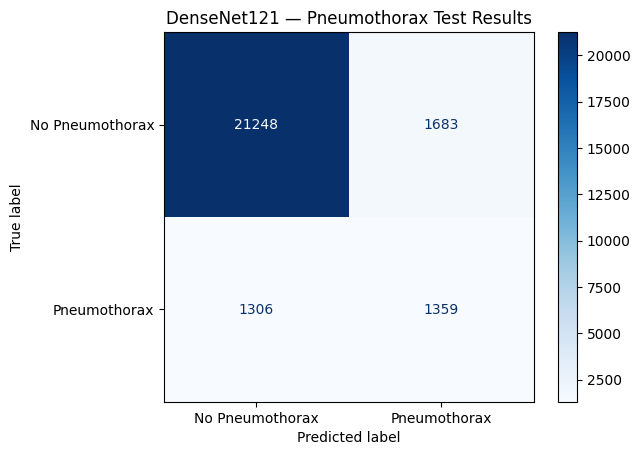

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Pneumothorax", "Pneumothorax"],
    cmap="Blues",
    values_format="d")

plt.title("DenseNet121 — Pneumothorax Test Results")
plt.show()

# **Calibration (is “70% confident” really right 70% of the time?)**

fitted temperature: 1.051
mean ECE before: 0.0157  after: 0.0135


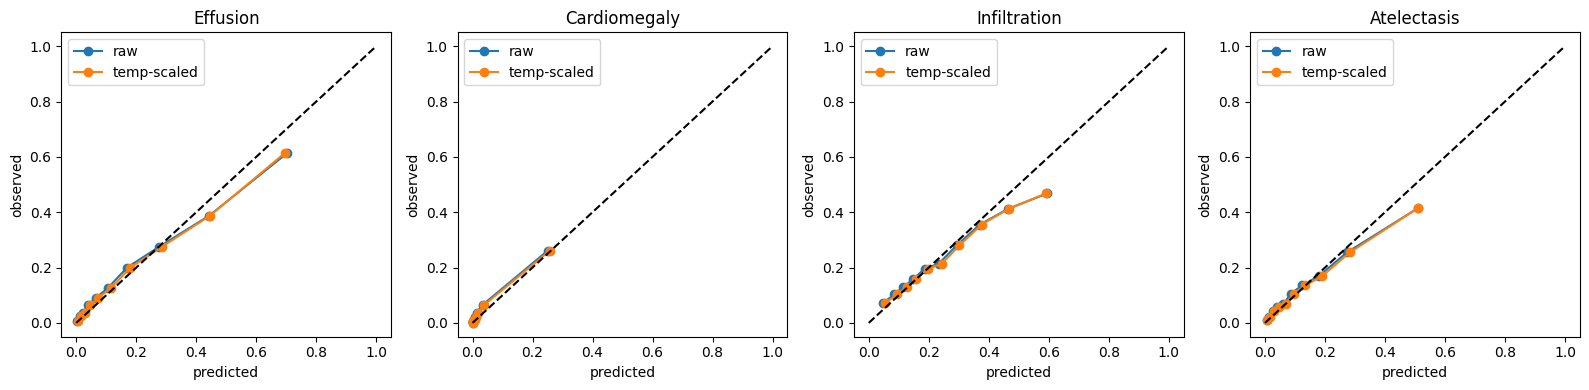

In [27]:
from sklearn.calibration import calibration_curve
from scipy.optimize import minimize_scalar

sig = lambda z: 1 / (1 + np.exp(-z))

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); tot = 0
    for a, b in zip(edges[:-1], edges[1:]):
        m = (p >= a) & ((p < b) if b < 1 else (p <= b))
        if m.any(): tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

def nll(T):
    p = np.clip(sig(Pva / T), 1e-7, 1 - 1e-7)
    return -np.mean(Yva * np.log(p) + (1 - Yva) * np.log(1 - p))
T = minimize_scalar(nll, bounds=(0.1, 10), method="bounded").x
print("fitted temperature:", round(T, 3))

before = [ece(Yte[:, i], sig(Pte[:, i])) for i in range(len(CLASSES))]
after = [ece(Yte[:, i], sig(Pte[:, i] / T)) for i in range(len(CLASSES))]
print("mean ECE before:", round(np.mean(before), 4), " after:", round(np.mean(after), 4))

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axs, ["Effusion", "Cardiomegaly", "Infiltration", "Atelectasis"]):
    i = CLASSES.index(c)
    for P, lab in [(sig(Pte[:, i]), "raw"), (sig(Pte[:, i] / T), "temp-scaled")]:
        fr, mp = calibration_curve(Yte[:, i], P, n_bins=10, strategy="quantile")
        ax.plot(mp, fr, marker="o", label=lab)
    ax.plot([0, 1], [0, 1], "k--"); ax.set_title(c); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend()
plt.tight_layout();
plt.savefig(
    f"{SAVE_DIR}/calibration_plots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Subgroup performance (sex and age) with confidence intervals**

In [18]:
rng = np.random.default_rng(0)

def mean_auc(Y, P):
    return np.mean([roc_auc_score(Y[:, i], P[:, i]) for i in range(Y.shape[1]) if 0 < Y[:, i].sum() < len(Y)])

def boot_ci(Y, P, n=100):
    vals = []
    for _ in range(n):
        s = rng.integers(0, len(Y), len(Y))
        vals.append(mean_auc(Y[s], P[s]))
    return np.percentile(vals, [2.5, 97.5])

age = test_df["age"].values
groups = {
    "Female": (test_df["sex"] == 0).values, "Male": (test_df["sex"] == 1).values,
    "Age < 40": age < 40, "Age 40-64": (age >= 40) & (age < 65), "Age 65+": age >= 65,
    "PA view": (test_df["view"] == 1).values, "AP view": (test_df["view"] == 0).values,
}
rows = []
for name, m in groups.items():
    lo, hi = boot_ci(Yte[m], Pte[m])
    rows.append([name, int(m.sum()), round(mean_auc(Yte[m], Pte[m]), 3), f"[{lo:.3f}, {hi:.3f}]"])
print(pd.DataFrame(rows, columns=["Group", "N", "Mean AUROC", "95% CI"]).to_string(index=False))

    Group     N  Mean AUROC         95% CI
   Female 10714       0.812 [0.807, 0.818]
     Male 14882       0.816 [0.812, 0.821]
 Age < 40  8290       0.774 [0.769, 0.820]
Age 40-64 13481       0.813 [0.807, 0.819]
  Age 65+  3825       0.792 [0.783, 0.801]
  PA view 11096       0.813 [0.807, 0.820]
  AP view 14500       0.790 [0.783, 0.795]


In [19]:
res2.to_csv("/content/drive/MyDrive/cxr/results_nih_test.csv")
print("saved")

saved


# **gradio**

In [22]:
!pip -q install gradio

In [29]:
import gradio as gr
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

model.eval()

def demo_predict(image, disease):
    if image is None:
        raise gr.Error("Please upload a chest X-ray.")


    im = Image.fromarray(image).convert("L")
    im = im.resize((256, 256), Image.Resampling.BILINEAR)


    im = im.crop((16, 16, 240, 240))

    pixels = np.asarray(im, dtype=np.float32) / 255.0
    x = torch.from_numpy(pixels).unsqueeze(0)
    x = ((x - 0.5) / 0.25).repeat(3, 1, 1)


    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(dev))
        scores = torch.sigmoid(logits)[0].cpu().numpy()

    predictions = {
        name: float(scores[i])
        for i, name in enumerate(CLASSES)}

    ci = CLASSES.index(disease)
    cam, _ = gradcam(x, ci)

    cmap = plt.get_cmap("jet")
    heatmap = cmap(cam)[..., :3]

    grayscale = np.stack([pixels] * 3, axis=-1)
    overlay = 0.6 * grayscale + 0.4 * heatmap
    overlay = (np.clip(overlay, 0, 1) * 255).astype(np.uint8)

    return predictions, overlay

demo = gr.Interface(
    fn=demo_predict,
    inputs=[
        gr.Image(type="numpy", label="Upload Chest X-ray"),
        gr.Dropdown(
            choices=CLASSES,
            value="Pneumothorax",
            label="Disease for Grad-CAM"
        )
    ],
    outputs=[
        gr.Label(num_top_classes=14, label="Disease Scores"),
        gr.Image(label="Grad-CAM Visualization")
    ],
    title="Chest X-ray AI — DenseNet121",
    description=(
        "Research demonstration only!!!"
        "Not intended for medical diagnosis or clinical use"
        "Scores are not guaranteed to be calibrated probabilities."))

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [28]:
print("=" * 55)
print("FINAL CHEST X-RAY MODEL RESULTS")
print("=" * 55)

print("\nModel comparison:")
print(res2.to_string())

print("\nMean AUROC across 14 diseases:")
print(f"DenseNet121: {np.mean(list(dl_auc.values())):.4f}")

print("\nPneumothorax test AUROC:")
print(f"{dl_auc['Pneumothorax']:.4f}")

print("\nModel checkpoint:")
print("Exists:", os.path.exists(CKPT))

print("\nAll results ready for README!")

FINAL CHEST X-RAY MODEL RESULTS

Model comparison:
                    DL only  DL+meta (GB)  DL+meta (LogReg)  Metadata only
Atelectasis           0.782         0.780             0.782          0.561
Cardiomegaly          0.887         0.874             0.886          0.506
Effusion              0.828         0.828             0.829          0.531
Infiltration          0.701         0.709             0.704          0.604
Mass                  0.832         0.823             0.832          0.505
Nodule                0.774         0.764             0.774          0.565
Pneumonia             0.724         0.702             0.723          0.524
Pneumothorax          0.860         0.849             0.856          0.588
Consolidation         0.754         0.741             0.751          0.612
Edema                 0.845         0.831             0.846          0.707
Emphysema             0.910         0.890             0.906          0.537
Fibrosis              0.827         0.816        